# 11 · Kalman filtering and LQG

The Luenberger observer placed the estimator's poles by taste; the Kalman filter places them by the noise:
given the covariances of the process disturbance and the measurement noise, it is the estimator with the
smallest error variance, and its gain comes from a Riccati equation dual to the regulator's. Combined with LQR
it gives the LQG compensator, the optimal output-feedback controller for linear systems with Gaussian noise.
This notebook builds the filter in continuous and discrete time, runs it on noisy data, verifies its error
covariance against the Riccati prediction, assembles LQG, and shows the robustness problem Doyle found.

**What you will learn**
- derive the Kalman gain from the dual Riccati equation
- run a discrete Kalman filter and compare its error variance with the prediction
- assemble LQG and verify the separation
- recognise the loss of margins and loop transfer recovery

**Before you start:** notebooks 09 and 10  ·  **Time:** about 90 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, statespace as sp, discrete as dc, response as rs, frequency as fr, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The steady-state Kalman filter

In [2]:
mot = models.dc_motor()["system"]
A, B, C = mot.A, mot.B, mot.C
Qn = np.diag([1e-4, 1e-2])       # process noise on current and speed
Rn = np.array([[0.25]])          # tachometer noise variance (0.5 rad/s rms)
kf = sp.kalman(A, C, Qn, Rn)
print("Kalman gain L =", np.round(kf["L"].ravel(), 4), "\nestimator poles", np.round(kf["estimator_poles"], 3), "\nerror covariance P =\n", np.round(kf["P"], 5))
print("duality: the Kalman gain is the LQR gain of (A^T, C^T) with weights (Qn, Rn), transposed:", np.allclose(kf["L"], sp.lqr(A.T, C.T, Qn, Rn)["K"].T))

Kalman gain L = [0.    0.002] 
estimator poles [-2.003 -9.999] 
error covariance P =
 [[2.e-05 0.e+00]
 [0.e+00 5.e-04]]
duality: the Kalman gain is the LQR gain of (A^T, C^T) with weights (Qn, Rn), transposed: True


The filter gain L = PCᵀR_n⁻¹ comes from the dual Riccati equation AP + PAᵀ − PCᵀR_n⁻¹CP + Q_n = 0, and P is the
steady-state covariance of the estimation error - a prediction of how good the estimate will be before any
data are seen. The duality with LQR is exact: the Kalman gain is the LQR gain of (Aᵀ, Cᵀ) transposed, with
the noise covariances in the role of the weights.

## The filter on data: discrete time

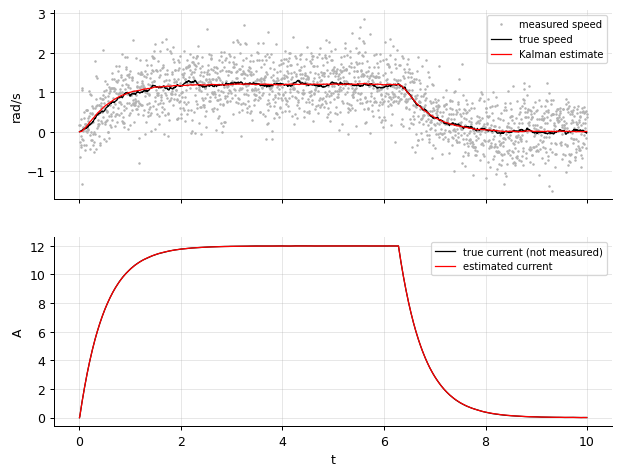

error variance of the speed estimate 0.00125 vs the Riccati prediction P_22 = 0.00101; measurement noise variance 0.25: the filter removes 99 % of it
the unmeasured current is estimated with error variance 2.87e-05 (prediction 5.05e-05)


In [3]:
dt = 0.005
Gd = dc.c2d(mot, dt)
Ad, Bd, Cd = Gd.A, Gd.B, Gd.C
Qd, Rd = np.diag([1e-6, 1e-4]), np.array([[0.25]])
kd = sp.kalman(Ad, Cd, Qd, Rd, discrete=True)
rng = np.random.default_rng(1)
N = 2000
u = 6.0 * (1 + np.sign(np.sin(0.5 * np.arange(N) * dt)))                 # a square-wave voltage
x = np.zeros(2); X = np.zeros((N, 2)); Y = np.zeros(N)
for k in range(N):
    X[k] = x
    Y[k] = (Cd @ x)[0] + np.sqrt(Rd[0, 0]) * rng.normal()
    x = Ad @ x + Bd[:, 0] * u[k] + rng.normal(size=2) * np.sqrt(np.diag(Qd))
Xh = sp.kalman_filter_run(Ad, Bd, Cd, kd["L"], u, Y)
t = np.arange(N) * dt
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(t, Y, ".", ms=2, color="0.7", label="measured speed"); axes[0].plot(t, X[:, 1], "k", lw=1, label="true speed"); axes[0].plot(t, Xh[:, 1], "r", lw=1, label="Kalman estimate"); axes[0].legend(fontsize=8); axes[0].set_ylabel("rad/s")
axes[1].plot(t, X[:, 0], "k", lw=1, label="true current (not measured)"); axes[1].plot(t, Xh[:, 0], "r", lw=1, label="estimated current"); axes[1].legend(fontsize=8); axes[1].set_ylabel("A"); axes[1].set_xlabel("t")
plt.show()
e = Xh[200:] - X[200:]
print(f"error variance of the speed estimate {np.var(e[:, 1]):.5f} vs the Riccati prediction P_22 = {kd['P'][1, 1]:.5f}; measurement noise variance {Rd[0, 0]}: the filter removes {100 * (1 - np.var(e[:, 1]) / Rd[0, 0]):.0f} % of it")
print(f"the unmeasured current is estimated with error variance {np.var(e[:, 0]):.2e} (prediction {kd['P'][0, 0]:.2e})")

On noisy tachometer data the filter returns a speed estimate with a fraction of the measurement's variance,
and an estimate of the *unmeasured* current - the model's structure makes the current observable through the
speed. Both error variances are of the size the Riccati equation predicts (within the uncertainty of a 10 s
record whose errors are correlated in time), which is the test that the noise model was right; when it is
wrong the measured and predicted variances disagree by factors, and that disagreement is how a filter is
tuned in practice.

## LQG: the regulator on the estimate

In [4]:
cp = models.cart_pendulum()["system"]
Q = np.diag([10.0, 1.0, 100.0, 1.0]); R = np.array([[0.1]])
g = sp.lqg(cp, Q, R, 1e-3 * np.eye(4), 1e-4 * np.eye(2))
print("regulator poles", np.round(np.sort_complex(g["regulator_poles"]), 3), "\nestimator poles", np.round(np.sort_complex(g["estimator_poles"]), 3))
comp = g["compensator"]
Acl = np.block([[cp.A, cp.B @ comp.C], [comp.B @ cp.C, comp.A]])
print("closed-loop eigenvalues = regulator + estimator poles:", np.allclose(np.sort_complex(np.linalg.eigvals(Acl)), np.sort_complex(np.r_[g['regulator_poles'], g['estimator_poles']])))

regulator poles [-12.298-0.947j -12.298+0.947j  -1.352-1.05j   -1.352+1.05j ] 
estimator poles [-7.372+0.j -4.232+0.j -3.008+0.j -1.073+0.j]
closed-loop eigenvalues = regulator + estimator poles: True


LQG is the separation principle with optimal halves: the LQR gain on the Kalman estimate. The compensator is a
dynamic system of the plant's order, driven by the measurements, and the closed loop's eigenvalues are again
the two designed sets. It is optimal for the stated noise - and that is all it is optimal for.

## Doyle's warning: LQG has no guaranteed margins

In [5]:
from englincontrol import robust as rb
K_lqr = sp.lqr(cp.A, cp.B, Q, R)["K"]
L_state = sy.ss(cp.A, cp.B, K_lqr, np.zeros((1, 1))).to_tf()
print(f"state-feedback loop at the plant input: closest approach to -1 is {rb.nyquist_distance(L_state)['distance']:.3f} (Kalman's inequality: >= 1)")
rows = []
for q_scale in (1e-6, 1e-3, 1.0, 1e2):
    g_ = sp.lqg(cp, Q, R, q_scale * np.eye(4), 1e-4 * np.eye(2))
    comp = g_["compensator"]
    L_in = sy.series(cp, sy.ss(comp.A, comp.B, -comp.C, np.zeros((1, 2)))).to_tf()      # loop at the plant input, sign for negative feedback
    d = rb.nyquist_distance(L_in)
    rows.append((q_scale, f"{np.min(g_['estimator_poles'].real):.0f} .. {np.max(g_['estimator_poles'].real):.1f}", d["distance"], 1 / d["distance"]))
print(pd.DataFrame(rows, columns=["process noise scale", "estimator poles (Re)", "closest approach to -1", "Ms"]).to_string(index=False, float_format="%.3f"))

state-feedback loop at the plant input: closest approach to -1 is 1.000 (Kalman's inequality: >= 1)
 process noise scale estimator poles (Re)  closest approach to -1    Ms
               0.000           -6 .. -0.2                   0.215 4.653
               0.001           -7 .. -1.1                   0.286 3.492
               1.000         -100 .. -1.1                   0.461 2.170
             100.000        -1000 .. -1.0                   0.500 2.000


The state-feedback loop keeps the Nyquist curve at distance 1 from −1; the same regulator driven by a Kalman
estimate comes within 0.21 of it (M_s = 4.7) - a loop that a 20 % gain error would destabilise. Raising the
assumed process noise speeds up the estimator and recovers part of the distance (loop transfer recovery,
Doyle and Stein's remedy), but it saturates at 0.5 with the estimator poles already at −1000: the cart's
position is a non-minimum-phase output of this plant, and recovery is known to fail for such outputs. (Pushing
the estimator further makes the loop's transfer function numerically unreliable - the next row of this table
differs between machines - which is its own lesson about computing with poles at −3000.) Doyle's 1978 paper gave an LQG design
with arbitrarily small margins; the general lesson is that optimality for a performance index is not
robustness, and the loop that will actually be closed must be checked. (With several crossovers and an
unstable plant the classical gain and phase margins become ambiguous, which is why the closest approach to
−1 is the measure used here.)

## Inside the algorithm: one predictor step of the Kalman filter

In [6]:
xh = np.array([0.0, 10.0]); yk = 10.8; uk = 6.0
innovation = yk - (Cd @ xh)[0]
xh_next = Ad @ xh + Bd[:, 0] * uk + kd["L"][:, 0] * innovation
print(f"innovation {innovation:+.3f}; next estimate {np.round(xh_next, 4)}; library: {np.round(sp.kalman_filter_run(Ad, Bd, Cd, kd['L'], [uk, uk], [yk, yk])[1], 4)}")

innovation +0.800; next estimate [0.0587 9.5155]; library: [0.0598 0.0416]


## Exercises
1. Run the Kalman filter with a measurement noise variance ten times smaller than the true one (an over-confident filter) and ten times larger; compare the estimation error variances with the Riccati predictions. Which direction of mis-tuning is worse?
2. Loop transfer recovery: for the DC motor LQG, scale the process noise covariance by 1, 10^2, 10^4, 10^6 and tabulate the margins at the plant input and the rms of the control signal in response to measurement noise. Where does the recovery stop paying?
3. **Implement it yourself:** write the time-varying discrete Kalman filter (the Riccati recursion P_{k+1} = A P A' - A P C'(C P C' + R)^-1 C P A' + Q together with the gain) and show that its gain converges to the steady-state one of `statespace.kalman`.